## Analysis extension #2 

This notebook stress-tests the **primary clean joint MLM** generated by AE1b. **IMPORTANT:** It no longer reads the historical `bert_dev_learned` checkpoint.

The model/data paths are read from `revision_audited_mlm/manifest.json`. By default AE2 uses the manifest's `primary_seed` (*seed 17*) for the detailed K-sensitivity/residual analysis; seed-to-seed joint-versus-development-only stability is handled in AE4.

The scope boundary remains unchanged: representation-level K sensitivity, cell/sample distributions, random-subspace calibration, held-out development, K-series-only residual PCA and technical/program diagnostics are **manuscript-eligible** here. Old three-axis foregut/ductal/acinar/biliary directional calculations are retained only as legacy machinery; final biological directions and their inference are in AE3.

(*note that in the notebook last running AE was labeled WP, work_package*)

## 0. Configuration

Run this notebook against the same data/model directory used by the existing Results notebooks. During debugging you can reduce the bootstrap/null iteration counts; restore the final values before producing revision figures/tables.

In [1]:
from pathlib import Path
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scanpy as sc
import scipy.sparse as sp
from scipy.stats import spearmanr
from scipy.linalg import subspace_angles

from sklearn.decomposition import PCA
from sklearn.model_selection import GroupShuffleSplit

import torch
from transformers import BertForMaskedLM

RNG_SEED = 20260918
rng = np.random.default_rng(RNG_SEED)

In [2]:
# ---- audited revision paths written by AE1b ----
DATA_ROOT = Path("/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data")
AUDITED_ROOT = DATA_ROOT / "revision_audited_mlm"
MANIFEST_PATH = AUDITED_ROOT / "manifest.json"

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"{MANIFEST_PATH}\nRun AE1b.ipynb first."
    )

with open(MANIFEST_PATH) as f:
    AUDIT_MANIFEST = json.load(f)

PRIMARY_SEED = int(AUDIT_MANIFEST["primary_seed"])
MODEL_DIR = Path(AUDIT_MANIFEST["models"]["joint"][str(PRIMARY_SEED)])
DEV_H5AD = Path(AUDIT_MANIFEST["dev_h5ad"])
CANCER_H5AD = Path(AUDIT_MANIFEST["cancer_h5ad"])

OUTDIR = AUDITED_ROOT / "analysis" / f"ae2_clean_joint_seed_{PRIMARY_SEED}"
OUTDIR.mkdir(parents=True, exist_ok=True)

print("AE2 primary seed:", PRIMARY_SEED)
print("Joint model:", MODEL_DIR)
print("Development:", DEV_H5AD)
print("Cancer:", CANCER_H5AD)
print("Outputs:", OUTDIR)

# ---- main analysis settings ----
K_ORIGINAL = 75
K_GRID_BASE = [10, 20, 30, 50, 75, 100, 125, 150]
VAR_THRESHOLDS = [0.70, 0.80, 0.90, 0.95]

N_INNER_BOOT = 200
N_OUTER_BOOT = 2000
N_RANDOM_SUBSPACES = 1000
N_RANDOM_DIRECTIONS = 100000
N_LABEL_PERM = 10000
N_HELDOUT_SPLITS = 10

TOP_RESIDUAL_PCS = 10
PROGRAM_MIN_GENES = 5

CONDITION_ORDER = ["N1", "N2", "K1", "K1.5", "K2", "K3", "K4", "K5", "K6"]
STATE_ORDER = ["ductal", "transitional", "malignant_ductal"]
TRANSITIONS = [
    ("ductal", "transitional", "early"),
    ("transitional", "malignant_ductal", "late"),
    ("ductal", "malignant_ductal", "total"),
]


AE2 primary seed: 17
Joint model: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/joint/seed_17/model
Development: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/development/A_dev_aligned_clean.h5ad
Cancer: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/pdac/A_cancer_aligned_clean.h5ad
Outputs: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/ae2_clean_joint_seed_17


## 1. Load the current MLM embedding and audited metadata

The model is **not retrained** here. We recompute deterministic CLS embeddings (`model.eval()`, no dropout) and align them to the exact developmental/cancer row blocks used by the token corpus.

In [3]:
@torch.no_grad()
def cls_embeddings(model, Xt, At, batch_size=32):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)
    model.eval()
    out_all = []
    for i in range(0, Xt.shape[0], batch_size):
        #x = torch.as_tensor(Xt[i:i+batch_size], dtype=torch.long, device=device)
        #a = torch.as_tensor(At[i:i+batch_size], dtype=torch.long, device=device)
        #the above gave some warnings
        x = torch.from_numpy(np.array(Xt[i:i+batch_size], copy=True)).long().to(device)
        a = torch.from_numpy(np.array(At[i:i+batch_size], copy=True)).long().to(device)
        out = model.bert(input_ids=x, attention_mask=a, return_dict=True)
        # Pipeline sequence is [DOM] [CLS] genes... [SEP] -> CLS at position 1.
        out_all.append(out.last_hidden_state[:, 1, :].cpu())
    return torch.cat(out_all, dim=0).numpy()

A_dev = sc.read_h5ad(DEV_H5AD)
A_can = sc.read_h5ad(CANCER_H5AD)

model = BertForMaskedLM.from_pretrained(MODEL_DIR)
with open(os.path.join(MODEL_DIR, "vocab_meta.json")) as f:
    vocab_meta = json.load(f)

X_tokens = np.load(os.path.join(MODEL_DIR, "X_tokens.npy"), mmap_mode="r")
X_attn = np.load(os.path.join(MODEL_DIR, "X_attn.npy"), mmap_mode="r")
domain = np.load(os.path.join(MODEL_DIR, "domain.npy"))

assert X_tokens.shape == X_attn.shape
assert domain.shape[0] == X_tokens.shape[0]
assert int((domain == 0).sum()) == A_dev.n_obs, "DEV token rows != DEV AnnData rows"
assert int((domain == 1).sum()) == A_can.n_obs, "Cancer token rows != cancer AnnData rows"
assert A_dev.n_vars == A_can.n_vars
assert np.array_equal(A_dev.var_names.to_numpy(), A_can.var_names.to_numpy())

X_dev_path = os.path.join(MODEL_DIR, "X_dev_cls.npy")
X_can_path = os.path.join(MODEL_DIR, "X_cancer_cls.npy")

dev_names_path = os.path.join(MODEL_DIR, "dev_obs_names.npy")
can_names_path = os.path.join(MODEL_DIR, "cancer_obs_names.npy")

X_dev = np.load(X_dev_path)
X_can = np.load(X_can_path)

dev_names = np.load(dev_names_path, allow_pickle=True)
can_names = np.load(can_names_path, allow_pickle=True)

assert np.array_equal(dev_names.astype(str), A_dev.obs_names.astype(str))
assert np.array_equal(can_names.astype(str), A_can.obs_names.astype(str))

print("Observation-name alignment checks passed.")
print("DEV CLS:", X_dev.shape)
print("Burdziak CLS:", X_can.shape)
print("DEV obs columns:", list(A_dev.obs.columns))

Observation-name alignment checks passed.
DEV CLS: (34760, 256)
Burdziak CLS: (28131, 256)
DEV obs columns: ['cell_id', 'keep', 'day', 'embryo_id', 'experimental_batch', 'cell_id_base', 'major_trajectory', 'celltype_update', 'endo_category', 'day_meta', 'dev_state_pancreas', 'dev_state_union', 'dev_day', 'source_file', 'dev_tier']


Numerical integrity *check*; embedding sets should be:
- Finite, centered very close to zero overall, on very similar scales, with standard deviation close to 1.
- That is what it is expected from BERT hidden states after layer normalization.

In [4]:
assert np.isfinite(X_dev).all()
assert np.isfinite(X_can).all()

print("DEV mean/std:", X_dev.mean(), X_dev.std())
print("CAN mean/std:", X_can.mean(), X_can.std())

DEV mean/std: -0.0030967726 0.964094
CAN mean/std: -0.00449156 0.97033983


In [5]:
# Required metadata checks for AE2.
required_can = ["condition", "cancer_state", "batch"]
missing_can = [c for c in required_can if c not in A_can.obs]
assert not missing_can, f"Missing cancer metadata: {missing_can}"

# In this loaded progression cohort the normal controls are N1/N2; all K* conditions
# are the tumor-progression query set for the malignant-only residual diagnostic.
can_obs = A_can.obs.copy()
can_obs["condition"] = can_obs["condition"].astype(str)
can_obs["cancer_state"] = can_obs["cancer_state"].astype(str)
can_obs["batch"] = can_obs["batch"].astype(str)
can_obs["is_normal_control"] = can_obs["condition"].isin(["N1", "N2"])
can_obs["is_tumor_progression"] = can_obs["condition"].str.startswith("K")

print(pd.crosstab(can_obs["condition"], can_obs["cancer_state"]))
print("\nSamples/batches per condition:")
print(can_obs[["batch", "condition"]].drop_duplicates()["condition"].value_counts().reindex(CONDITION_ORDER))

# A batch should not mix progression conditions/states. If this fails, stop and inspect.
assert (can_obs.groupby("batch")["condition"].nunique() <= 1).all()
assert (can_obs.groupby("batch")["cancer_state"].nunique() <= 1).all()

cancer_state  ductal  malignant_ductal  transitional
condition                                           
K1                 0                 0          4503
K1.5               0                 0          2476
K2                 0                 0          2079
K3                 0                 0          3338
K4                 0                 0          1254
K5                 0              5364             0
K6                 0              3491             0
N1              3225                 0             0
N2              2401                 0             0

Samples/batches per condition:
condition
N1      2
N2      2
K1      3
K1.5    2
K2      2
K3      2
K4      2
K5      3
K6      3
Name: count, dtype: int64


## 2. Core geometry helpers and full developmental PCA

The developmental mean is the origin. 
- PCA is fit to **development only**, exactly as in the current analysis. 
- We fit the full PCA once and take nested prefixes of the component basis for the K sweep; this is numerically cleaner and faster than refitting separate PCAs for every K.

In [6]:
def projection_metrics(X_centered, basis):
    coords = X_centered @ basis
    recon = coords @ basis.T
    residual = X_centered - recon
    proj_sq = np.sum(recon**2, axis=1)
    res_sq = np.sum(residual**2, axis=1)
    q = proj_sq / (proj_sq + res_sq + 1e-12)
    global_fraction = proj_sq.sum() / (proj_sq.sum() + res_sq.sum() + 1e-12)
    return coords, recon, residual, q, global_fraction


def dev_clean_labels(obs):
    mapping = {
        "foregut_other": "foregut",
        "pancreas_ductal_proxy": "ductal",
        "pancreas_acinar": "acinar",
        "biliary": "biliary",
        "pancreas_islet": "islet",
    }
    if "endo_category" not in obs:
        raise KeyError("A_dev.obs['endo_category'] is required for the existing reference directions.")
    return obs["endo_category"].astype(str).map(mapping).fillna("other").to_numpy()


def centroids_by_label(X, labels):
    labels = np.asarray(labels).astype(str)
    return {s: X[labels == s].mean(axis=0) for s in np.unique(labels)}


def cos_sim(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))


def developmental_axes(dev_pc, labels_dev):
    C = centroids_by_label(dev_pc, labels_dev)
    needed = ["foregut", "ductal", "acinar", "biliary"]
    missing = [x for x in needed if x not in C]
    if missing:
        raise ValueError(f"Missing developmental labels for existing axes: {missing}")
    return {
        "foregut_to_ductal": C["ductal"] - C["foregut"],
        "foregut_to_acinar": C["acinar"] - C["foregut"],
        "foregut_to_biliary": C["biliary"] - C["foregut"],
    }


def between_group_fraction(X, groups):
    """Descriptive fraction of total squared dispersion attributable to group centroids."""
    X = np.asarray(X)
    g = np.asarray(groups).astype(str)
    grand = X.mean(axis=0)
    total = np.sum((X - grand)**2)
    between = 0.0
    for lab in np.unique(g):
        Xi = X[g == lab]
        if len(Xi) == 0:
            continue
        between += len(Xi) * np.sum((Xi.mean(axis=0) - grand)**2)
    return float(between / (total + 1e-12))


def residual_top_variance(residual, n_top=10):
    X = residual - residual.mean(axis=0)
    max_rank = min(X.shape[0]-1, X.shape[1])
    n = min(n_top, max_rank)
    if n < 1:
        return np.nan, None
    p = PCA(n_components=n, svd_solver="full").fit(X)
    return float(p.explained_variance_ratio_.sum()), p


mu_dev = X_dev.mean(axis=0)
Xd = X_dev - mu_dev
Xc = X_can - mu_dev
D = Xd.shape[1]

# Full orthonormal PCA basis (D is only 256 in the audited model).
pca_dev_full = PCA(n_components=min(D, Xd.shape[0]-1), svd_solver="full")
pca_dev_full.fit(Xd)
full_basis = pca_dev_full.components_.T
cumvar = np.cumsum(pca_dev_full.explained_variance_ratio_)

k_by_var = {thr: int(np.searchsorted(cumvar, thr) + 1) for thr in VAR_THRESHOLDS}
K_GRID = sorted(set([k for k in K_GRID_BASE if k <= full_basis.shape[1]] + list(k_by_var.values())))

print("Embedding dimension D =", D)
print("K at variance thresholds:", k_by_var)
print("K sweep:", K_GRID)
print(f"Cumulative DEV variance at K={K_ORIGINAL}: {cumvar[K_ORIGINAL-1]:.4f}")

Embedding dimension D = 256
K at variance thresholds: {0.7: 13, 0.8: 17, 0.9: 24, 0.95: 39}
K sweep: [10, 13, 17, 20, 24, 30, 39, 50, 75, 100, 125, 150]
Cumulative DEV variance at K=75: 0.9800


# 3. K sensitivity

For every K we record four distinct things rather than defending K=75 as uniquely correct:

1. **Per-cell developmental projection** by state/condition.
2. **Malignant transition geometry**: fraction of each state displacement inside the developmental subspace and cosine to each existing developmental endpoint direction.
3. **Residual structure** among K1–K6 cells: how much residual dispersion is associated with progression labels and how low-dimensional the residual remains.
4. **Residual subspace stability** relative to K=75, using principal angles among the leading residual PCs.

Absolute projection scores must rise as K rises. The relevant question is whether the *ordering and directional conclusion* are stable across a broad regime.

In [7]:
labels_dev = dev_clean_labels(A_dev.obs)
labels_state = can_obs["cancer_state"].to_numpy()
labels_condition = can_obs["condition"].to_numpy()
tumor_mask = can_obs["is_tumor_progression"].to_numpy()

k_summary_rows = []
k_state_rows = []
k_condition_rows = []
k_transition_rows = []
residual_pca_by_k = {}

for K in K_GRID:
    basis = full_basis[:, :K]
    Xd_pc, _, _, q_dev, dev_global = projection_metrics(Xd, basis)
    Xc_pc, _, residual, q_can, can_global = projection_metrics(Xc, basis)
    axes = developmental_axes(Xd_pc, labels_dev)

    # State/condition projection summaries.
    for name, groups, collector in [
        ("state", labels_state, k_state_rows),
        ("condition", labels_condition, k_condition_rows),
    ]:
        for g in pd.unique(groups):
            vals = q_can[groups == g]
            collector.append({
                "K": K, name: g, "n_cells": len(vals),
                "q_mean": float(np.mean(vals)),
                "q_median": float(np.median(vals)),
                "q_q25": float(np.quantile(vals, 0.25)),
                "q_q75": float(np.quantile(vals, 0.75)),
            })

    # Residual structure among tumor-progression K1-K6 cells only.
    res_t = residual[tumor_mask]
    top10_var, p_res = residual_top_variance(res_t, TOP_RESIDUAL_PCS)
    residual_pca_by_k[K] = p_res
    eta_condition = between_group_fraction(res_t, labels_condition[tumor_mask])
    eta_state = between_group_fraction(res_t, labels_state[tumor_mask])

    k_summary_rows.append({
        "K": K,
        "dev_cumulative_variance": float(cumvar[K-1]),
        "dev_global_projection_fraction": dev_global,
        "cancer_global_projection_fraction": can_global,
        "cancer_q_median": float(np.median(q_can)),
        "tumor_residual_top10_variance_fraction": top10_var,
        "tumor_residual_between_condition_fraction": eta_condition,
        "tumor_residual_between_state_fraction": eta_state,
    })

    # Coarse malignant progression transitions.
    C_full = centroids_by_label(Xc, labels_state)
    C_pc = centroids_by_label(Xc_pc, labels_state)
    for s1, s2, tname in TRANSITIONS:
        v_full = C_full[s2] - C_full[s1]
        v_pc = C_pc[s2] - C_pc[s1]
        proj_sq = np.sum(v_pc**2)  # basis is orthonormal
        full_sq = np.sum(v_full**2)
        row = {
            "K": K, "transition": tname,
            "from_state": s1, "to_state": s2,
            "displacement_norm": float(np.sqrt(full_sq)),
            "fraction_in_dev_subspace": float(proj_sq / (full_sq + 1e-12)),
        }
        for aname, avec in axes.items():
            row[f"cos_{aname}"] = cos_sim(v_pc, avec)
        row["max_abs_dev_cosine"] = max(abs(row[f"cos_{a}"]) for a in axes)
        k_transition_rows.append(row)

k_summary = pd.DataFrame(k_summary_rows)
k_state = pd.DataFrame(k_state_rows)
k_condition = pd.DataFrame(k_condition_rows)
k_transitions = pd.DataFrame(k_transition_rows)

# Residual leading-subspace similarity to K=75 (or nearest available K).
K_ref = K_ORIGINAL if K_ORIGINAL in residual_pca_by_k else min(K_GRID, key=lambda x: abs(x-K_ORIGINAL))
ref_p = residual_pca_by_k[K_ref]
subspace_rows = []
for K, p in residual_pca_by_k.items():
    m = min(TOP_RESIDUAL_PCS, p.components_.shape[0], ref_p.components_.shape[0])
    ang = subspace_angles(ref_p.components_[:m].T, p.components_[:m].T)
    subspace_rows.append({
        "K": K,
        "reference_K": K_ref,
        "n_residual_pcs": m,
        "mean_cos2_principal_angle": float(np.mean(np.cos(ang)**2)),
        "max_principal_angle_deg": float(np.degrees(np.max(ang))),
    })
residual_subspace_stability = pd.DataFrame(subspace_rows)

k_summary = k_summary.merge(residual_subspace_stability[["K","mean_cos2_principal_angle","max_principal_angle_deg"]], on="K")

k_summary.to_csv(os.path.join(OUTDIR, "k_sensitivity_summary.csv"), index=False)
k_state.to_csv(os.path.join(OUTDIR, "k_sensitivity_by_state.csv"), index=False)
k_condition.to_csv(os.path.join(OUTDIR, "k_sensitivity_by_condition.csv"), index=False)
k_transitions.to_csv(os.path.join(OUTDIR, "k_sensitivity_transition_geometry.csv"), index=False)
residual_subspace_stability.to_csv(os.path.join(OUTDIR, "k_sensitivity_residual_subspace_stability.csv"), index=False)

k_summary

,K,dev_cumulative_variance,dev_global_projection_fraction,cancer_global_projection_fraction,cancer_q_median,tumor_residual_top10_variance_fraction,tumor_residual_between_condition_fraction,tumor_residual_between_state_fraction,mean_cos2_principal_angle,max_principal_angle_deg
0,10,0.601866,0.601866,0.083519,0.076593,0.667255,0.180541,0.078527,0.462614,87.076111
1,13,0.704865,0.704865,0.106722,0.101122,0.665019,0.177201,0.076990,0.485960,87.489540
2,17,0.812205,0.812205,0.131646,0.124870,0.662761,0.179155,0.078624,0.511034,81.422424
3,20,0.861934,0.861934,0.147815,0.139687,0.661672,0.181119,0.079019,0.541482,76.623077
4,24,0.900116,0.900116,0.169021,0.163280,0.663381,0.181784,0.079462,0.555879,71.195824
5,30,0.927944,0.927944,0.238672,0.232648,0.663420,0.182494,0.080801,0.574916,72.963509
6,39,0.950132,0.950132,0.321324,0.313419,0.667464,0.185959,0.083223,0.601199,81.386703
7,50,0.963905,0.963905,0.394331,0.389695,0.672887,0.188657,0.087086,0.662590,81.387321
8,75,0.979956,0.979955,0.546546,0.545879,0.667350,0.188078,0.086798,1.000000,0.000047
9,100,0.987924,0.987924,0.666962,0.665710,0.687095,0.198136,0.099197,0.693393,51.237720


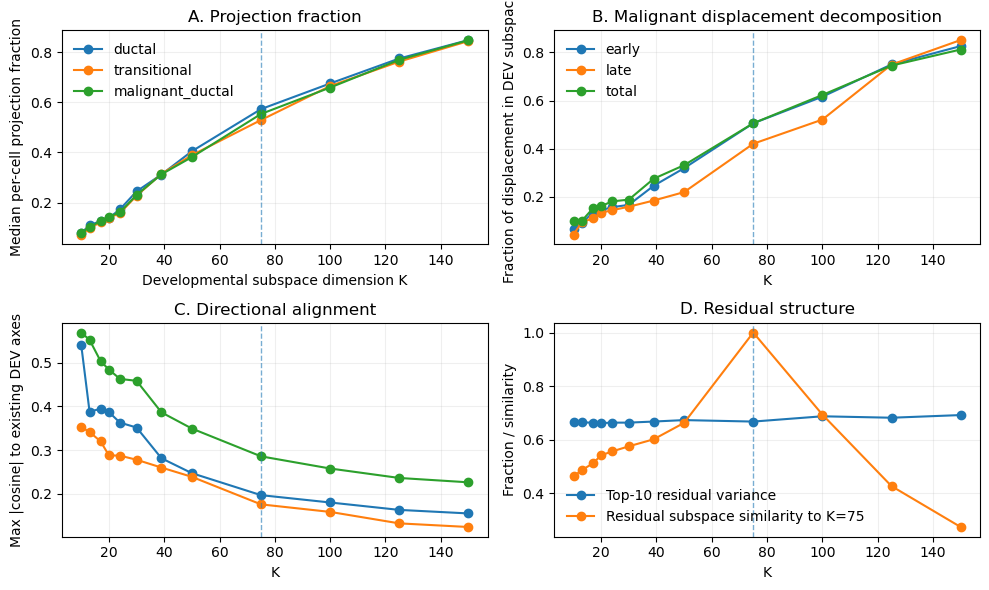

In [8]:
# Compact K-sensitivity figure.
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

# A: projection by coarse state
ax = axes[0,0]
for state in STATE_ORDER:
    sub = k_state[k_state["state"] == state].sort_values("K")
    if len(sub):
        ax.plot(sub["K"], sub["q_median"], marker="o", label=state)
ax.set_xlabel("Developmental subspace dimension K")
ax.set_ylabel("Median per-cell projection fraction")
ax.set_title("A. Projection fraction")
ax.legend(frameon=False)

# B: transition developmental fraction
ax = axes[0,1]
for t in ["early","late","total"]:
    sub = k_transitions[k_transitions["transition"] == t].sort_values("K")
    ax.plot(sub["K"], sub["fraction_in_dev_subspace"], marker="o", label=t)
ax.set_xlabel("K")
ax.set_ylabel("Fraction of displacement in DEV subspace")
ax.set_title("B. Malignant displacement decomposition")
ax.legend(frameon=False)

# C: max absolute developmental cosine
ax = axes[1,0]
for t in ["early","late","total"]:
    sub = k_transitions[k_transitions["transition"] == t].sort_values("K")
    ax.plot(sub["K"], sub["max_abs_dev_cosine"], marker="o", label=t)
ax.set_xlabel("K")
ax.set_ylabel("Max |cosine| to existing DEV axes")
ax.set_title("C. Directional alignment")

# D: residual structure + stability
ax = axes[1,1]
ax.plot(k_summary["K"], k_summary["tumor_residual_top10_variance_fraction"], marker="o", label="Top-10 residual variance")
ax.plot(k_summary["K"], k_summary["mean_cos2_principal_angle"], marker="o", label=f"Residual subspace similarity to K={K_ref}")
ax.set_xlabel("K")
ax.set_ylabel("Fraction / similarity")
ax.set_title("D. Residual structure")
ax.legend(frameon=False)

for ax in axes.ravel():
    ax.axvline(K_ORIGINAL, linestyle="--", linewidth=1, alpha=0.6)
    ax.grid(alpha=0.2)

plt.tight_layout()
fig.savefig(os.path.join(OUTDIR, "k_sensitivity_overview.pdf"), bbox_inches="tight")
plt.show()

## 4. Fixed-K cell-level distributions and sample-level summaries

The original histogram is replaced by distributions that retain **condition/state and biological sample**. N1 and N2 are kept separate here because Reviewer 3's criticism is specifically about normal-control structure.

In [9]:
K = min(K_ORIGINAL, full_basis.shape[1])
basis = full_basis[:, :K]
Xd_pc, _, _, q_dev, dev_global = projection_metrics(Xd, basis)
Xc_pc, Xc_recon, residual_all, q_can, can_global = projection_metrics(Xc, basis)
residual_norm = np.linalg.norm(residual_all, axis=1)
axes_K = developmental_axes(Xd_pc, labels_dev)

cell_metrics = can_obs[["batch","condition","cancer_state","is_normal_control","is_tumor_progression"]].copy()
cell_metrics["projection_fraction"] = q_can
cell_metrics["residual_norm"] = residual_norm
cell_metrics.index.name = "cell_id"
cell_metrics.to_csv(os.path.join(OUTDIR, f"cell_metrics_K{K}.csv"))

sample_metrics = (
    cell_metrics.reset_index()
    .groupby(["batch","condition","cancer_state"], as_index=False)
    .agg(
        n_cells=("cell_id","size"),
        projection_median=("projection_fraction","median"),
        projection_mean=("projection_fraction","mean"),
        residual_norm_median=("residual_norm","median"),
        residual_norm_mean=("residual_norm","mean"),
    )
)
sample_metrics.to_csv(os.path.join(OUTDIR, f"sample_metrics_K{K}.csv"), index=False)
sample_metrics

,batch,condition,cancer_state,n_cells,projection_median,projection_mean,residual_norm_median,residual_norm_mean
0,Ag-Lung-Mets-Kate,K6,malignant_ductal,302,0.543394,0.547222,11.209726,11.192521
1,Ag-PDAC-PT-Kate,K5,malignant_ductal,2386,0.554693,0.553629,10.838435,10.816713
2,D396_EPI,K1.5,transitional,1062,0.527400,0.535840,11.275602,11.157936
3,DACC963LIVERmet,K6,malignant_ductal,1747,0.548873,0.547000,11.136950,11.108213
4,DACC963PT_Kate_plus,K5,malignant_ductal,241,0.538248,0.536465,11.152432,11.155953
5,DACC963_mKate_plus,K6,malignant_ductal,1442,0.541070,0.542659,11.172045,11.121196
6,DACD351_Kate_plus,K1,transitional,1963,0.523914,0.526686,11.302872,11.230990
7,DACD394_Kate_plus,K1,transitional,1395,0.527443,0.531414,11.285363,11.223340
8,DACD403_Kate_plus,N2,ductal,636,0.500577,0.505322,11.054846,11.009048
9,DACD404_Kate_plus,K2,transitional,1057,0.530143,0.534204,11.247254,11.061418


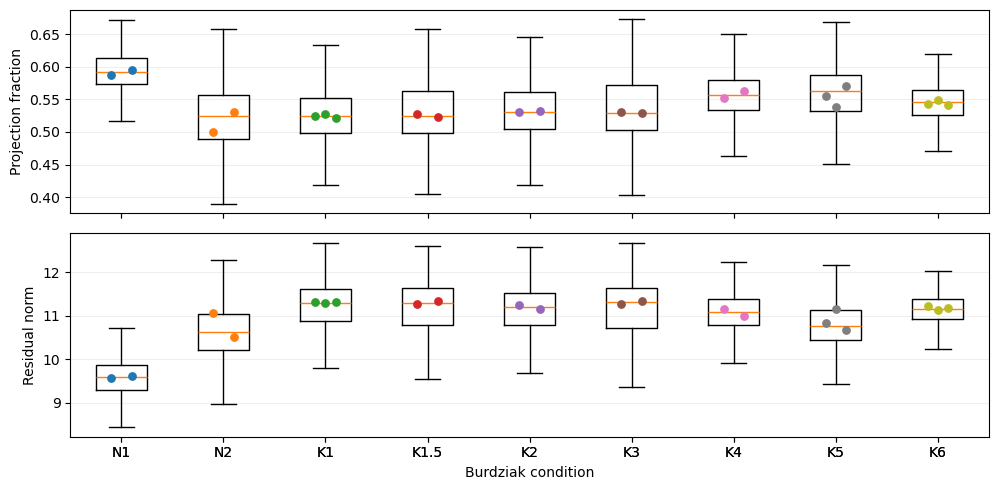

In [10]:
# Cell-level boxplots by progression condition + sample medians as visible points.
conds = [c for c in CONDITION_ORDER if c in set(cell_metrics["condition"])]
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

for ax, metric, ylabel in [
    (axes[0], "projection_fraction", "Projection fraction"),
    (axes[1], "residual_norm", "Residual norm"),
]:
    data = [cell_metrics.loc[cell_metrics["condition"] == c, metric].to_numpy() for c in conds]
    ax.boxplot(data, tick_labels=conds, showfliers=False)
    # sample medians overlaid; jitter deterministic by sample rank
    sm = sample_metrics[sample_metrics["condition"].isin(conds)].copy()
    ycol = "projection_median" if metric == "projection_fraction" else "residual_norm_median"
    for j, c in enumerate(conds, start=1):
        vals = sm.loc[sm["condition"] == c, ycol].to_numpy()
        if len(vals):
            offsets = np.linspace(-0.10, 0.10, len(vals)) if len(vals) > 1 else np.array([0.0])
            ax.scatter(j + offsets, vals, s=28, zorder=3)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.2)

axes[1].set_xlabel("Burdziak condition")
plt.tight_layout()
fig.savefig(os.path.join(OUTDIR, f"cell_and_sample_distributions_K{K}.pdf"), bbox_inches="tight")
plt.show()


## 5. Hierarchical bootstrap: sample first, then cells within sample — legacy axes

This section is retained to document how biological-sample uncertainty was handled in the original directional analysis. The biological sample (`batch` in the Burdziak object) is the primary unit and cells are resampled within samples.

**Important:** the bootstrap implementation is valid, but the developmental axes supplied to it in AE2 are the old three-axis definitions. Do not use the resulting axis-specific intervals as the final biological result. The same sample-first logic is reapplied to the revised directions in **AE3 FINAL**.

- Thus, this documents and stress-tests the statistical resampling strategy on the *legacy* directional setup.

In [11]:
def precompute_within_sample_boot_centroids(X_pc, obs, sample_col="batch", n_inner=200, seed=1):
    rr = np.random.default_rng(seed)
    out = {}
    for sample, idx_names in obs.groupby(sample_col).groups.items():
        # pandas group indices here are cell IDs; convert to positional indices
        pos = obs.index.get_indexer(pd.Index(idx_names))
        Xi = X_pc[pos]
        n = Xi.shape[0]
        B = np.empty((n_inner, Xi.shape[1]), dtype=np.float32)
        for b in range(n_inner):
            draw = rr.integers(0, n, size=n)
            B[b] = Xi[draw].mean(axis=0)
        out[str(sample)] = B
    return out


def hierarchical_bootstrap_transitions(X_pc, obs, dev_axes, n_inner=200, n_outer=2000, seed=1):
    rr = np.random.default_rng(seed)
    inner = precompute_within_sample_boot_centroids(X_pc, obs, n_inner=n_inner, seed=seed+11)

    sample_meta = obs[["batch","cancer_state"]].drop_duplicates().copy()
    samples_by_state = {
        s: sample_meta.loc[sample_meta["cancer_state"] == s, "batch"].astype(str).tolist()
        for s in STATE_ORDER
    }
    for s, samples in samples_by_state.items():
        if len(samples) < 2:
            warnings.warn(f"State {s} has only {len(samples)} biological sample(s); bootstrap inference is weak.")

    rows = []
    for b in range(n_outer):
        C = {}
        for state, samples in samples_by_state.items():
            picked = rr.choice(samples, size=len(samples), replace=True)
            sample_centroids = []
            for sample in picked:
                arr = inner[str(sample)]
                sample_centroids.append(arr[rr.integers(0, arr.shape[0])])
            C[state] = np.mean(sample_centroids, axis=0)

        for s1, s2, tname in TRANSITIONS:
            v = C[s2] - C[s1]
            row = {
                "bootstrap": b,
                "transition": tname,
                "pc_displacement_norm": float(np.linalg.norm(v)),
            }
            for aname, avec in dev_axes.items():
                row[f"cos_{aname}"] = cos_sim(v, avec)
            row["max_abs_dev_cosine"] = max(abs(row[f"cos_{a}"]) for a in dev_axes)
            rows.append(row)
    return pd.DataFrame(rows)

boot = hierarchical_bootstrap_transitions(
    Xc_pc, can_obs, axes_K,
    n_inner=N_INNER_BOOT, n_outer=N_OUTER_BOOT, seed=RNG_SEED
)
boot.to_csv(os.path.join(OUTDIR, f"hierarchical_bootstrap_transition_metrics_K{K}.csv"), index=False)

# Observed equal-sample-weight centroids: this is the point estimate paired with the hierarchical CI.
obs_sample_pc = {}
for state in STATE_ORDER:
    sample_means = []
    submeta = can_obs.loc[can_obs["cancer_state"] == state]
    for sample, idx_names in submeta.groupby("batch").groups.items():
        pos = can_obs.index.get_indexer(pd.Index(idx_names))
        sample_means.append(Xc_pc[pos].mean(axis=0))
    obs_sample_pc[state] = np.mean(np.stack(sample_means), axis=0)

observed_metric = {}
for s1, s2, tname in TRANSITIONS:
    v = obs_sample_pc[s2] - obs_sample_pc[s1]
    observed_metric[(tname, "pc_displacement_norm")] = float(np.linalg.norm(v))
    for aname, avec in axes_K.items():
        observed_metric[(tname, f"cos_{aname}")] = cos_sim(v, avec)
    observed_metric[(tname, "max_abs_dev_cosine")] = max(
        abs(observed_metric[(tname, f"cos_{a}")]) for a in axes_K
    )

summary_rows = []
for t in ["early","late","total"]:
    sub = boot[boot["transition"] == t]
    for col in [c for c in boot.columns if c.startswith("cos_")] + ["max_abs_dev_cosine", "pc_displacement_norm"]:
        vals = sub[col].to_numpy()
        summary_rows.append({
            "transition": t,
            "metric": col,
            "observed_equal_sample_weight": observed_metric[(t, col)],
            "bootstrap_median": float(np.median(vals)),
            "ci025": float(np.quantile(vals, 0.025)),
            "ci975": float(np.quantile(vals, 0.975)),
        })
boot_summary = pd.DataFrame(summary_rows)
boot_summary.to_csv(os.path.join(OUTDIR, f"hierarchical_bootstrap_summary_K{K}.csv"), index=False)
boot_summary

,transition,metric,observed_equal_sample_weight,bootstrap_median,ci025,ci975
0,early,cos_foregut_to_ductal,0.045605,0.044703,0.003353,0.073614
1,early,cos_foregut_to_acinar,-0.202288,-0.193712,-0.218543,-0.165876
2,early,cos_foregut_to_biliary,0.217344,0.212715,0.129805,0.280811
3,early,max_abs_dev_cosine,0.217344,0.214737,0.167775,0.280811
4,early,pc_displacement_norm,6.805946,6.948444,5.973788,9.231377
5,late,cos_foregut_to_ductal,0.084472,0.077115,-0.003889,0.161980
6,late,cos_foregut_to_acinar,-0.151531,-0.142010,-0.200645,-0.059523
7,late,cos_foregut_to_biliary,-0.129878,-0.121627,-0.212321,-0.015384
8,late,max_abs_dev_cosine,0.151531,0.156324,0.105434,0.216387
9,late,pc_displacement_norm,4.332615,4.704802,4.196962,5.547008



# 6. Explicit null models

These controls answer different questions and should not be collapsed into one p-value.

- **Random matched-dimensional subspace — FINAL:** asks whether the developmental subspace captures more Burdziak variation than arbitrary K-dimensional orientations in the same joint embedding.
- **Held-out development — FINAL:** checks reconstruction outside the cells used to fit developmental PCA.
- **Random direction — LEGACY AXES:** useful geometric benchmark, but its final version belongs in AE3 because the old developmental directions were redefined.
- **Sample-label permutation — LEGACY AXES:** implementation is retained for reproducibility; final revised-direction inference is in AE3 FINAL.

AE4, not this held-out-PCA analysis, addresses whether malignant cells influenced representation learning itself.


### 6A. Random matched-dimensional subspaces

For speed and exactness at the *variance-fraction* level, the null is computed from each group's covariance matrix. For a random orthonormal basis Q, the captured fraction is `trace(Qᵀ C Q) / trace(C)`.

In [12]:
def covariance_second_moment(X):
    # Centering is already relative to the developmental mean, which is the reference origin.
    return (X.T @ X) / X.shape[0]


def captured_fraction_from_cov(C, Q):
    return float(np.trace(Q.T @ C @ Q) / (np.trace(C) + 1e-12))


def random_orthonormal_basis(D, K, rr):
    G = rr.normal(size=(D, K))
    Q, _ = np.linalg.qr(G, mode="reduced")
    return Q

# Observed groups: all Burdziak + coarse states.
groups_for_null = {"all_burdziak": np.ones(Xc.shape[0], dtype=bool)}
for s in STATE_ORDER:
    groups_for_null[f"state_{s}"] = labels_state == s

covs = {name: covariance_second_moment(Xc[mask]) for name, mask in groups_for_null.items()}
obs_frac = {name: captured_fraction_from_cov(C, basis) for name, C in covs.items()}

rr = np.random.default_rng(RNG_SEED + 100)
null_rows = []
for b in range(N_RANDOM_SUBSPACES):
    Q = random_orthonormal_basis(D, K, rr)
    for name, C in covs.items():
        null_rows.append({"null_iter": b, "group": name, "fraction": captured_fraction_from_cov(C, Q)})

random_subspace_null = pd.DataFrame(null_rows)
random_subspace_null.to_csv(os.path.join(OUTDIR, f"random_subspace_null_K{K}.csv"), index=False)

rs_summary = []
for name, obs_val in obs_frac.items():
    vals = random_subspace_null.loc[random_subspace_null["group"] == name, "fraction"].to_numpy()
    rs_summary.append({
        "group": name,
        "observed_dev_subspace_fraction": obs_val,
        "null_median": float(np.median(vals)),
        "null_q025": float(np.quantile(vals, 0.025)),
        "null_q975": float(np.quantile(vals, 0.975)),
        "percentile_of_observed": float(np.mean(vals <= obs_val)),
        "upper_tail_empirical_p": float((1 + np.sum(vals >= obs_val)) / (len(vals) + 1)),
    })
random_subspace_summary = pd.DataFrame(rs_summary)
random_subspace_summary.to_csv(os.path.join(OUTDIR, f"random_subspace_summary_K{K}.csv"), index=False)
random_subspace_summary

,group,observed_dev_subspace_fraction,null_median,null_q025,null_q975,percentile_of_observed,upper_tail_empirical_p
0,all_burdziak,0.546546,0.292157,0.258064,0.332184,1.0,0.000999
1,state_ductal,0.564623,0.293051,0.250917,0.338529,1.0,0.000999
2,state_transitional,0.535982,0.292545,0.253545,0.336611,1.0,0.000999
3,state_malignant_ductal,0.553027,0.290863,0.250985,0.338155,1.0,0.000999



### 6B. Random-direction cosine benchmark - legacy developmental axes

The calculation below is preserved as an audit of the original analysis. Because AE3 replaces the old three developmental directions, these particular p-values/percentiles are **not manuscript-final**. AE3 FINAL repeats the random-direction benchmark using the revised Qiu-supported directions.


In [14]:
axis_names = list(axes_K)
A_axes = np.column_stack([axes_K[a] / (np.linalg.norm(axes_K[a]) + 1e-12) for a in axis_names])

# Observed cell-weighted state centroids, matching the core geometry.
Cpc = centroids_by_label(Xc_pc, labels_state)
obs_transition = {}
for s1, s2, tname in TRANSITIONS:
    v = Cpc[s2] - Cpc[s1]
    obs_transition[tname] = {
        "max_abs": max(abs(cos_sim(v, axes_K[a])) for a in axis_names),
        **{f"cos_{a}": cos_sim(v, axes_K[a]) for a in axis_names}
    }

rr = np.random.default_rng(RNG_SEED + 200)
R = rr.normal(size=(N_RANDOM_DIRECTIONS, K))
R /= np.linalg.norm(R, axis=1, keepdims=True) + 1e-12
cos_null = R @ A_axes
max_abs_null = np.max(np.abs(cos_null), axis=1)

rd_rows = []
for tname, obsvals in obs_transition.items():
    obs = obsvals["max_abs"]
    rd_rows.append({
        "transition": tname,
        "observed_max_abs_cosine": obs,
        "null_median_max_abs_cosine": float(np.median(max_abs_null)),
        "null_q025": float(np.quantile(max_abs_null, 0.025)),
        "null_q975": float(np.quantile(max_abs_null, 0.975)),
        "percentile_of_observed": float(np.mean(max_abs_null <= obs)),
        "upper_tail_empirical_p": float((1 + np.sum(max_abs_null >= obs)) / (len(max_abs_null) + 1)),
    })
random_direction_summary = pd.DataFrame(rd_rows)
random_direction_summary.to_csv(os.path.join(OUTDIR, f"random_direction_summary_K{K}.csv"), index=False)
random_direction_summary

,transition,observed_max_abs_cosine,null_median_max_abs_cosine,null_q025,null_q975,percentile_of_observed,upper_tail_empirical_p
0,early,0.196356,0.136339,0.038872,0.2964,0.78930,0.210708
1,late,0.175189,0.136339,0.038872,0.2964,0.70373,0.296277
2,total,0.285491,0.136339,0.038872,0.2964,0.96733,0.032680



### 6C. Sample-level state-label permutation - legacy developmental axes

The sample-level permutation logic is appropriate because each biological sample is the inferential unit. However, the axis-specific outputs below use the original developmental axes and are retained only for reproducibility. Final directional inference is regenerated in AE3 FINAL.


In [14]:
# Sample centroids in DEV-PC space.
sample_centroid_rows = []
for batch, idx_names in can_obs.groupby("batch").groups.items():
    pos = can_obs.index.get_indexer(pd.Index(idx_names))
    sample_centroid_rows.append({
        "batch": str(batch),
        "condition": can_obs.iloc[pos[0]]["condition"],
        "cancer_state": can_obs.iloc[pos[0]]["cancer_state"],
        "centroid": Xc_pc[pos].mean(axis=0),
    })
sample_centroids = pd.DataFrame(sample_centroid_rows)


def state_centroids_from_sample_table(df, label_col="cancer_state"):
    out = {}
    for state in STATE_ORDER:
        arrs = df.loc[df[label_col] == state, "centroid"].tolist()
        if not arrs:
            return None
        out[state] = np.mean(np.stack(arrs), axis=0)
    return out

C_sample_obs = state_centroids_from_sample_table(sample_centroids)
obs_sample_rows = []
for s1, s2, tname in TRANSITIONS:
    v = C_sample_obs[s2] - C_sample_obs[s1]
    obs_sample_rows.append({
        "transition": tname,
        **{f"cos_{a}": cos_sim(v, axes_K[a]) for a in axis_names},
        "max_abs_dev_cosine": max(abs(cos_sim(v, axes_K[a])) for a in axis_names),
    })
obs_sample_df = pd.DataFrame(obs_sample_rows).set_index("transition")

rr = np.random.default_rng(RNG_SEED + 300)
original_labels = sample_centroids["cancer_state"].to_numpy().copy()
perm_rows = []
for b in range(N_LABEL_PERM):
    tmp = sample_centroids.copy()
    tmp["perm_state"] = rr.permutation(original_labels)
    Cperm = state_centroids_from_sample_table(tmp, label_col="perm_state")
    for s1, s2, tname in TRANSITIONS:
        v = Cperm[s2] - Cperm[s1]
        row = {"perm_iter": b, "transition": tname}
        for a in axis_names:
            row[f"cos_{a}"] = cos_sim(v, axes_K[a])
        row["max_abs_dev_cosine"] = max(abs(row[f"cos_{a}"]) for a in axis_names)
        perm_rows.append(row)

label_perm = pd.DataFrame(perm_rows)
label_perm.to_csv(os.path.join(OUTDIR, f"sample_label_permutation_null_K{K}.csv"), index=False)

perm_summary_rows = []
for t in ["early","late","total"]:
    vals = label_perm.loc[label_perm["transition"] == t, "max_abs_dev_cosine"].to_numpy()
    obs = float(obs_sample_df.loc[t, "max_abs_dev_cosine"])
    perm_summary_rows.append({
        "transition": t,
        "observed_sample_equal_max_abs_cosine": obs,
        "null_median": float(np.median(vals)),
        "null_q025": float(np.quantile(vals, 0.025)),
        "null_q975": float(np.quantile(vals, 0.975)),
        "percentile_of_observed": float(np.mean(vals <= obs)),
    })
label_perm_summary = pd.DataFrame(perm_summary_rows)
label_perm_summary.to_csv(os.path.join(OUTDIR, f"sample_label_permutation_summary_K{K}.csv"), index=False)
label_perm_summary

,transition,observed_sample_equal_max_abs_cosine,null_median,null_q025,null_q975,percentile_of_observed
0,early,0.217344,0.175691,0.056423,0.302055,0.7176
1,late,0.151531,0.175496,0.056155,0.299981,0.3714
2,total,0.281779,0.176024,0.059236,0.302511,0.9456


### 6D. Held-out developmental cells

Use `embryo_id` as the grouping variable when available, so held-out cells come from held-out embryos rather than merely held-out cells from the same embryo. This is an out-of-sample PCA calibration **within the current jointly trained embedding**.

In [15]:
def q_against_basis(X_centered, basis):
    Z = X_centered @ basis
    proj_sq = np.sum(Z**2, axis=1)
    full_sq = np.sum(X_centered**2, axis=1)
    return proj_sq / (full_sq + 1e-12)

heldout_rows = []
if "embryo_id" in A_dev.obs and A_dev.obs["embryo_id"].notna().sum() > 0:
    groups = A_dev.obs["embryo_id"].astype(str).to_numpy()
    splitter = GroupShuffleSplit(n_splits=N_HELDOUT_SPLITS, test_size=0.2, random_state=RNG_SEED)
    split_iter = splitter.split(X_dev, groups=groups)
    split_mode = "embryo_id"
else:
    warnings.warn("No usable embryo_id; falling back to random cell split. Prefer embryo-level split for the revision.")
    idx = np.arange(X_dev.shape[0])
    rr = np.random.default_rng(RNG_SEED)
    splits = []
    for _ in range(N_HELDOUT_SPLITS):
        perm = rr.permutation(idx)
        n_test = int(0.2 * len(idx))
        splits.append((perm[n_test:], perm[:n_test]))
    split_iter = iter(splits)
    split_mode = "cell"

for s, (train_idx, test_idx) in enumerate(split_iter):
    mu_train = X_dev[train_idx].mean(axis=0)
    Xtr = X_dev[train_idx] - mu_train
    Xte = X_dev[test_idx] - mu_train
    Xcq = X_can - mu_train
    p = PCA(n_components=K, svd_solver="randomized", random_state=RNG_SEED+s).fit(Xtr)
    B = p.components_.T
    q_tr = q_against_basis(Xtr, B)
    q_te = q_against_basis(Xte, B)
    q_cq = q_against_basis(Xcq, B)
    heldout_rows.append({
        "split": s, "split_mode": split_mode,
        "n_train": len(train_idx), "n_test": len(test_idx),
        "train_dev_q_median": float(np.median(q_tr)),
        "heldout_dev_q_median": float(np.median(q_te)),
        "heldout_dev_q_q25": float(np.quantile(q_te,0.25)),
        "heldout_dev_q_q75": float(np.quantile(q_te,0.75)),
        "cancer_q_median_same_basis": float(np.median(q_cq)),
    })
heldout_dev = pd.DataFrame(heldout_rows)
heldout_dev.to_csv(os.path.join(OUTDIR, f"heldout_development_K{K}.csv"), index=False)
heldout_dev

,split,split_mode,n_train,n_test,train_dev_q_median,heldout_dev_q_median,heldout_dev_q_q25,heldout_dev_q_q75,cancer_q_median_same_basis
0,0,embryo_id,31691,3069,0.980501,0.979365,0.974588,0.983312,0.544677
1,1,embryo_id,29121,5639,0.980439,0.979885,0.974593,0.983989,0.541336
2,2,embryo_id,30570,4190,0.980751,0.977938,0.972645,0.982544,0.537526
3,3,embryo_id,22119,12641,0.980358,0.978724,0.972926,0.983284,0.546221
4,4,embryo_id,31332,3428,0.980494,0.979300,0.974229,0.983424,0.545271
5,5,embryo_id,29754,5006,0.980662,0.978884,0.973414,0.983217,0.544567
6,6,embryo_id,30772,3988,0.980558,0.978706,0.973013,0.983099,0.542190
7,7,embryo_id,25943,8817,0.980682,0.979464,0.974028,0.983749,0.550154
8,8,embryo_id,29836,4924,0.980722,0.978532,0.973217,0.983007,0.536098
9,9,embryo_id,28822,5938,0.980167,0.981147,0.975927,0.985130,0.547171


# 7. Malignant/tumor-progression-only residual PCA and N1/N2 diagnostic

This is the critical Reviewer-3 diagnostic. The developmental projection is unchanged; what changes is **which cells are allowed to define the residual PCA axes**.

- Fit the residual PCA on **K1–K6 only**.
- Project N1/N2 into that fixed malignant-defined residual space afterward.
- Compare this with the original residual PCA fit on all Burdziak cells.
- Ask whether the K1–K6 residual remains low-dimensional and whether the same cancer-associated programs remain associated with some leading residual axis.

In [15]:
# Original all-Burdziak residual PCA (for comparison only).
res_all_center = residual_all - residual_all.mean(axis=0)
n_res = min(50, residual_all.shape[1], residual_all.shape[0]-1)
pca_res_all = PCA(n_components=n_res, svd_solver="full").fit(res_all_center)
coords_res_all = pca_res_all.transform(res_all_center)

# Tumor-progression-only residual PCA. N1/N2 do not define these axes.
res_tumor = residual_all[tumor_mask]
mu_res_tumor = res_tumor.mean(axis=0)
pca_res_tumor = PCA(n_components=n_res, svd_solver="full").fit(res_tumor - mu_res_tumor)
coords_res_tumor_defined_all = pca_res_tumor.transform(residual_all - mu_res_tumor)
coords_res_tumor = coords_res_tumor_defined_all[tumor_mask]

print("Original all-Burdziak residual PCA, top 10 variance:", pca_res_all.explained_variance_ratio_[:10].sum())
print("Tumor-only residual PCA, top 10 variance:", pca_res_tumor.explained_variance_ratio_[:10].sum())

m = min(TOP_RESIDUAL_PCS, pca_res_all.components_.shape[0], pca_res_tumor.components_.shape[0])
angles = subspace_angles(pca_res_all.components_[:m].T, pca_res_tumor.components_[:m].T)
print("Leading residual subspace mean cos^2:", np.mean(np.cos(angles)**2))
print("Largest principal angle (deg):", np.degrees(np.max(angles)))

# Save per-cell malignant-defined coordinates.
res_score_df = can_obs[["batch","condition","cancer_state","is_normal_control","is_tumor_progression"]].copy()
for j in range(min(10, coords_res_tumor_defined_all.shape[1])):
    res_score_df[f"TumorResPC{j+1}"] = coords_res_tumor_defined_all[:, j]
res_score_df["development_projection_fraction"] = q_can
res_score_df["development_residual_norm"] = residual_norm
res_score_df.to_csv(os.path.join(OUTDIR, f"tumor_defined_residual_scores_K{K}.csv"))

Original all-Burdziak residual PCA, top 10 variance: 0.66423094
Tumor-only residual PCA, top 10 variance: 0.6673499
Leading residual subspace mean cos^2: 0.8480361
Largest principal angle (deg): 88.25291


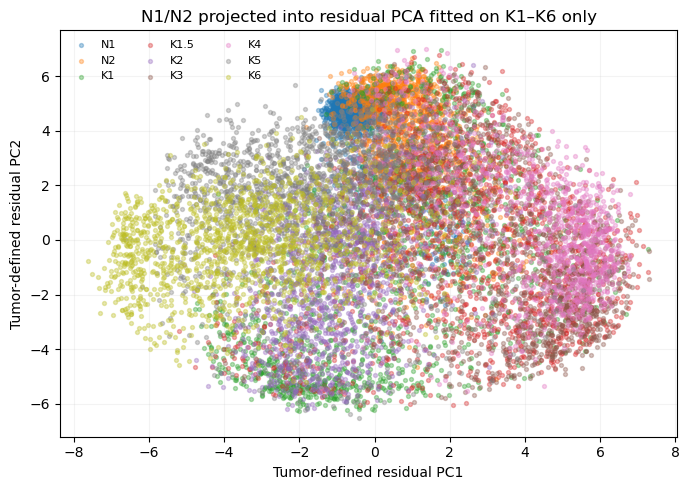

In [16]:
# Plot tumor-defined residual PC1/PC2. N1/N2 are references; they did not define the PCA.
fig, ax = plt.subplots(figsize=(7,5))
for cond in [c for c in CONDITION_ORDER if c in set(can_obs["condition"])]:
    msk = can_obs["condition"].to_numpy() == cond
    # Downsample for display only.
    idx = np.flatnonzero(msk)
    if len(idx) > 1500:
        idx = rng.choice(idx, size=1500, replace=False)
    ax.scatter(coords_res_tumor_defined_all[idx,0], coords_res_tumor_defined_all[idx,1], s=8, alpha=0.35, label=cond)
ax.set_xlabel("Tumor-defined residual PC1")
ax.set_ylabel("Tumor-defined residual PC2")
ax.set_title("N1/N2 projected into residual PCA fitted on K1–K6 only")
ax.legend(ncol=3, fontsize=8, frameon=False)
ax.grid(alpha=0.15)
plt.tight_layout()
fig.savefig(os.path.join(OUTDIR, f"tumor_defined_residual_pc1_pc2_K{K}.pdf"), bbox_inches="tight")
plt.show()

In [17]:
# N1/N2 and progression summaries by biological sample.
res_pc_cols = [f"TumorResPC{i+1}" for i in range(min(5, coords_res_tumor_defined_all.shape[1]))]
res_by_sample = (
    res_score_df.reset_index()
    .groupby(["batch","condition","cancer_state"], as_index=False)
    .agg({
        **{c:"median" for c in res_pc_cols},
        "development_projection_fraction":"median",
        "development_residual_norm":"median",
    })
)
res_by_sample.to_csv(os.path.join(OUTDIR, f"tumor_defined_residual_by_sample_K{K}.csv"), index=False)
res_by_sample

,batch,condition,cancer_state,TumorResPC1,TumorResPC2,TumorResPC3,TumorResPC4,TumorResPC5,development_projection_fraction,development_residual_norm
0,Ag-Lung-Mets-Kate,K6,malignant_ductal,-0.092817,0.986266,0.798218,0.611276,0.412232,0.543394,11.209726
1,Ag-PDAC-PT-Kate,K5,malignant_ductal,-2.084963,1.850534,-0.792922,-0.250786,-0.836600,0.554693,10.838435
2,D396_EPI,K1.5,transitional,2.401361,-0.886633,0.564570,-0.241410,-0.643124,0.527400,11.275602
3,DACC963LIVERmet,K6,malignant_ductal,-4.692780,-0.429680,2.839480,1.482112,2.734220,0.548873,11.136950
4,DACC963PT_Kate_plus,K5,malignant_ductal,-4.147133,-0.828820,0.965429,1.636722,1.311081,0.538248,11.152432
5,DACC963_mKate_plus,K6,malignant_ductal,-3.056653,0.101872,4.042250,1.455618,2.395247,0.541070,11.172045
6,DACD351_Kate_plus,K1,transitional,0.412846,-2.512243,-1.528904,-0.841733,-0.301684,0.523914,11.302872
7,DACD394_Kate_plus,K1,transitional,0.538518,-0.843948,-1.012895,-1.054673,-0.261041,0.527443,11.285363
8,DACD403_Kate_plus,N2,ductal,0.761917,3.869200,0.585365,-1.320363,-0.056963,0.500577,11.054846
9,DACD404_Kate_plus,K2,transitional,-0.860184,-1.044169,-1.496036,-2.635191,-1.017181,0.530143,11.247254


### 7A. Optional reverse diagnostic: residual directions present in N1/N2 alone

Fit a PCA to N1/N2 residuals only, then ask what fraction of each tumor-progression residual displacement lies in that normal-control residual span. A high fraction—especially for the late or total malignant displacement—would argue that some supposedly malignant residual structure is actually generic adult/normal-control or cross-dataset structure.

In [18]:
normal_mask = can_obs["is_normal_control"].to_numpy()
res_normal = residual_all[normal_mask]
mu_res_normal = res_normal.mean(axis=0)
normal_rank = min(30, res_normal.shape[1], res_normal.shape[0]-1)
pca_res_normal = PCA(n_components=normal_rank, svd_solver="full").fit(res_normal - mu_res_normal)
B_normal_res = pca_res_normal.components_.T

C_full = centroids_by_label(Xc, labels_state)
normal_span_rows = []
for s1, s2, tname in TRANSITIONS:
    v = C_full[s2] - C_full[s1]
    v_dev = (v @ basis) @ basis.T
    v_res = v - v_dev
    frac_in_normal_res_span = np.sum((v_res @ B_normal_res)**2) / (np.sum(v_res**2) + 1e-12)
    normal_span_rows.append({
        "transition": tname,
        "residual_displacement_norm": float(np.linalg.norm(v_res)),
        "fraction_of_residual_displacement_in_N1N2_residual_span": float(frac_in_normal_res_span),
        "N1N2_residual_PC_rank": normal_rank,
        "N1N2_residual_variance_explained": float(pca_res_normal.explained_variance_ratio_.sum()),
    })
normal_residual_span = pd.DataFrame(normal_span_rows)
normal_residual_span.to_csv(os.path.join(OUTDIR, f"N1N2_residual_span_alignment_K{K}.csv"), index=False)
normal_residual_span

,transition,residual_displacement_norm,fraction_of_residual_displacement_in_N1N2_residual_span,N1N2_residual_PC_rank,N1N2_residual_variance_explained
0,early,7.208439,0.880404,30,0.910189
1,late,5.061184,0.381087,30,0.910189
2,total,7.529774,0.713739,30,0.910189


But we want sample-equal computations: first calculate the mean embedding of each experimental sample (batch), then average those sample means within each state.

In [ ]:

# ============================================================
# N1/N2 residual-span alignment — SAMPLE-EQUAL centroids
# ============================================================

# Compute SAMPLE-EQUAL malignant-state centroids (NEW)
def sample_equal_centroids(X, obs):
    """
    First average cells within each experimental sample (batch).
    Then average sample centroids equally within each cancer state.
    """
    obs = obs[["cancer_state", "batch"]].copy()
    obs = obs.reset_index(drop=True)

    assert len(obs) == X.shape[0], "Metadata/embedding mismatch"

    obs["cancer_state"] = obs["cancer_state"].astype(str)
    obs["batch"] = obs["batch"].astype(str)
    obs["_pos"] = np.arange(len(obs))

    sample_means = {}

    for (state, batch), group in obs.groupby(
        ["cancer_state", "batch"],
        observed=True
    ):
        pos = group["_pos"].to_numpy(dtype=int)

        sample_means.setdefault(state, []).append(
            X[pos].mean(axis=0)
        )

    C = {
        state: np.mean(np.stack(means), axis=0)
        for state, means in sample_means.items()
    }

    print("Number of samples per state:")
    for state, means in sample_means.items():
        print(f"  {state}: {len(means)}")

    return C


# Centroids in the FULL development-centered embedding
C_full = sample_equal_centroids(Xc, can_obs)


# Calculate malignant residual displacements (UNCHANGED)
normal_span_rows = []

for s1, s2, tname in TRANSITIONS:

    v = C_full[s2] - C_full[s1]

    v_dev = (v @ basis) @ basis.T
    v_res = v - v_dev

    frac_in_normal_res_span = (
        np.sum((v_res @ B_normal_res)**2)
        / (np.sum(v_res**2) + 1e-12)
    )

    normal_span_rows.append({
        "transition": tname,
        "residual_displacement_norm": float(np.linalg.norm(v_res)),
        "fraction_of_residual_displacement_in_N1N2_residual_span": float(frac_in_normal_res_span),
        "N1N2_residual_PC_rank": normal_rank,
        "N1N2_residual_variance_explained": float(pca_res_normal.explained_variance_ratio_.sum()),
    })


# 4. Save separately to preserve original results
normal_residual_span = pd.DataFrame(normal_span_rows)

normal_residual_span.to_csv(
    os.path.join(
        OUTDIR,
        f"N1N2_residual_span_alignment_SAMPLE_EQUAL_K{K}.csv"
    ),
    index=False
)

display(normal_residual_span)


Number of samples per state:
  ductal: 4
  malignant_ductal: 6
  transitional: 11


,transition,residual_displacement_norm,fraction_of_residual_displacement_in_N1N2_residual_span,N1N2_residual_PC_rank,N1N2_residual_variance_explained
0,early,6.723424,0.869593,30,0.910189
1,late,5.193541,0.382950,30,0.910189
2,total,7.420162,0.695601,30,0.910189


# 8. Technical/sample covariate diagnostics

A residual PC should not be interpreted biologically if it is primarily tracking sequencing depth or one sample. We therefore check:

- log total counts,
- detected-gene count,
- existing epithelial score,
- a curated cell-cycle program score (computed below),
- condition association,
- sample (`batch`) association, including sample association **after removing condition means**.

`batch` is treated as the biological-sample identifier in the current object, so a batch association is not automatically a technical artifact; the within-condition diagnostic is the more relevant warning sign.

In [20]:
CANCER_PROGRAMS_MOUSE = {
    "emt_invasion": [
        "Vim", "Fn1", "Zeb1", "Zeb2", "Snai1", "Snai2", "Twist1",
        "Cdh2", "Itga5", "Itgav", "Itgb1", "Mmp2", "Mmp9", "Mmp14",
        "Col1a1", "Col1a2", "Col3a1", "Sparc", "Tnc", "Lox", "Postn"
    ],

    "epithelial_identity": [
        "Epcam", "Cdh1", "Krt8", "Krt18", "Krt19", "Krt7",
        "Cldn3", "Cldn4", "Cldn7", "Ocln", "Tjp1", "Muc1"
    ],

    "inflammatory_signaling": [
        "Nfkb1", "Nfkb2", "Rela", "Relb", "Tnf", "Tnfaip3",
        "Il1a", "Il1b", "Il6", "Cxcl1", "Cxcl2", "Cxcl10",
        "Ccl2", "Ccl5", "Ptgs2", "Socs3", "Icam1"
    ],

    "interferon_response": [
        "Stat1", "Stat2", "Irf1", "Irf7", "Irf9",
        "Isg15", "Ifit1", "Ifit2", "Ifit3", "Ifitm1", "Ifitm2", "Ifitm3",
        "Oas1a", "Oas1g", "Oas2", "Oas3", "Mx1", 
        "Rsad2", "Usp18", "Dhx58"
    ],

    "hypoxia": [
        "Hif1a", "Vegfa", "Slc2a1", "Ldha", "Pdk1",
        "Eno1", "Aldoa", "Bnip3", "Ndrg1", "Adm", "Car9",
        "Serpine1", "Ero1a", "Ankrd37"
    ],

    "oxidative_stress": [
        "Nfe2l2", "Keap1", "Hmox1", "Nqo1", "Gclc", "Gclm",
        "Gsr", "Gpx2", "Gpx4", "Prdx1", "Txn1",
        "Txnrd1", "Srxn1", "Sqstm1", "Ftl1", "Fth1"
    ],

    "unfolded_protein_response": [
        "Hspa5", "Hsp90b1", "Ddit3", "Atf3", "Atf4", "Atf6",
        "Xbp1", "Ern1", "Eif2ak3", "Pdia3", "Pdia4", "Pdia6",
        "Dnajb9", "Herpud1", "Derl3", "Manf", "Creld2"
    ],

    "kras_mapk_signaling": [
        "Dusp4", "Dusp5", "Dusp6", "Etv1", "Etv4", "Etv5",
        "Spry1", "Spry2", "Spry4", "Fos", "Fosl1", "Jun", "Junb",
        "Egr1", "Egr2", "Ets1", "Myc", "Mapk1", "Mapk3"
    ],

    "myc_targets": [
        "Myc", "Max", "Mxd1", "Npm1", "Ncl", "Odc1", "Cad",
        "Nme1", "Nme2", "Hspd1", "Hspe1", "Tfrc", "Slc2a1",
        "Phb", "Pa2g4", "Hnrnpa1", "Hnrnpa2b1", "Eif4a1"
    ],

    "p53_pathway": [
        "Trp53", "Cdkn1a", "Mdm2", "Bax", "Bbc3", "Pmaip1",
        "Gadd45a", "Gadd45g", "Sesn1", "Sesn2", "Ddb2",
        "Phlda3", "Zmat3", "Rrm2b", "Ccng1"
    ],

    "cell_cycle": [
        "Mki67", "Top2a", "Pcna", "Mcm2", "Mcm3", "Mcm4",
        "Mcm5", "Mcm6", "Mcm7", "Cdk1", "Ccnb1", "Ccnb2",
        "Cenpa", "Cenpe", "Cenpf", "Tpx2", "Bub1b", "Ube2c",
        "Aspm", "Nusap1", "Kif11", "Kif20b"
    ],

    "dna_damage_repair": [
        "Brca1", "Brca2", "Rad51", "Rad51ap1", "Msh2", "Msh6",
        "Pms2", "Pcna", "Rpa1", "Rpa2", "Chek1", "Chek2",
        "Atm", "Atr", "Fanca", "Fancc", "Xrcc5", "Xrcc6"
    ],

    "glycolysis_metabolic_rewiring": [
        "Slc2a1", "Hk1", "Hk2", "Pfkl", "Pfkp", "Aldoa",
        "Gapdh", "Pgam1", "Eno1", "Pkm", "Ldha",
        "Pdk1", "Slc16a3"
    ],

    "oxidative_phosphorylation_mitochondrial": [
        "Ndufa2", "Ndufa4", "Ndufb3", "Ndufb5",
        "Sdha", "Sdhb", "Uqcrc1", "Uqcrc2", "Cyc1",
        "Cox4i1", "Cox5a", "Atp5f1a", "Atp5f1b", "Atp5mc1"
    ],

    "ecm_remodeling_invasion": [
        "Fn1", "Col1a1", "Col1a2", "Col3a1", "Col4a1", "Col4a2",
        "Col5a1", "Col5a2", "Sparc", "Tnc", "Postn", "Lox",
        "Loxl2", "Mmp2", "Mmp9", "Mmp14", "Itga5", "Itgav",
        "Itgb1", "Vcan", "Thbs1"
    ],

    "antigen_presentation_mhc_i": [
        "B2m", "H2-K1", "H2-D1", "Tap1", "Tap2",
        "Tapbp", "Psmb8", "Psmb9", "Psmb10", "Nlrc5"
    ],

    "antigen_presentation_mhc_ii": [
        "H2-Aa", "H2-Ab1", "H2-Eb1", "Cd74", "Ciita",
        "H2-DMa", "H2-DMb1", "H2-Ob"
    ],

    "stemness_progenitor_like": [
        "Sox9", "Prom1", "Aldh1a1", "Aldh1a3", "Lgr5",
        "Krt19", "Epcam", "Tacstd2", "Muc1", "Nes",
        "Vim", "Lgals1", "S100a10"
    ],

    "therapy_resistance_stress_tolerance": [
        "Aldh1a1", "Aldh1a3", "Abcb1a", "Abcb1b", "Abcc1",
        "Abcc3", "Abcg2", "Bcl2", "Bcl2l1", "Mcl1",
        "Hspa1a", "Hspa1b", "Hspa5", "Hmox1", "Nqo1",
        "Sod2", "Gpx2", "Lgals1", "Tgfb1", "Vim"
    ],

    "tgfb_signaling": [
        "Tgfb1", "Tgfb2", "Tgfbr1", "Tgfbr2", "Smad2", "Smad3",
        "Smad4", "Serpine1", "Id1", "Id2",
        "Id3", "Skil", "Snai1", "Snai2"
    ],

    "apoptosis": [
        "Bax", "Bak1", "Bbc3", "Pmaip1", "Casp3", "Casp7",
        "Casp8", "Casp9", "Apaf1", "Bid", "Bad", "Bcl2",
        "Bcl2l1", "Mcl1"
    ],

    "senescence_sasp": [
        "Cdkn1a", "Cdkn2a", "Trp53", "Il6", "Cxcl1", "Cxcl2",
        "Ccl2", "Serpine1", "Mmp3", "Mmp9", "Igfbp3",
        "Igfbp5", "Gadd45a"
    ],

    "ap1_immediate_early_response": [
       "Fos", "Fosb", "Fosl1", "Fosl2",
        "Jun", "Junb", "Jund",
        "Atf3", "Egr1", "Egr2",
        "Dusp1", "Dusp5", "Dusp6",
        "Ier2", "Csrnp1", "Zfp36",
        "Btg2", "Ccn1", "Klf6"
    ]
}

In [21]:
def raw_total_counts_and_detected_genes(adata):
    X = adata.X
    if sp.issparse(X):
        total = np.asarray(X.sum(axis=1)).ravel()
        detected = np.asarray((X > 0).sum(axis=1)).ravel()
    else:
        X = np.asarray(X)
        total = X.sum(axis=1)
        detected = (X > 0).sum(axis=1)
    return total, detected


def score_programs_log1p_cpm(adata, programs, target_sum=1e4, min_genes=5, gene_symbol_col="symbol"):
    """Mean log1p library-normalized expression across present program genes, without densifying all genes."""
    X = adata.X.tocsr() if sp.issparse(adata.X) else np.asarray(adata.X)
    if gene_symbol_col in adata.var:
        symbols = adata.var[gene_symbol_col].astype(str).to_numpy()
    else:
        symbols = adata.var_names.astype(str).to_numpy()
    gene_to_idx = {}
    for i,g in enumerate(symbols):
        gene_to_idx.setdefault(g, i)

    if sp.issparse(X):
        totals = np.asarray(X.sum(axis=1)).ravel()
    else:
        totals = X.sum(axis=1)
    scale = target_sum / np.maximum(totals, 1.0)

    out = {}
    coverage = []
    for pname, genes in programs.items():
        present = [g for g in genes if g in gene_to_idx]
        coverage.append({"program":pname,"n_total":len(genes),"n_present":len(present),"fraction_present":len(present)/max(len(genes),1)})
        if len(present) < min_genes:
            continue
        idx = [gene_to_idx[g] for g in present]
        if sp.issparse(X):
            Xi = X[:, idx].toarray()
        else:
            Xi = X[:, idx]
        Xi = np.log1p(Xi * scale[:,None])
        out[pname] = Xi.mean(axis=1)
    return pd.DataFrame(out, index=adata.obs_names), pd.DataFrame(coverage)


def eta_squared(values, groups):
    y = np.asarray(values, dtype=float)
    g = np.asarray(groups).astype(str)
    grand = np.nanmean(y)
    total = np.nansum((y-grand)**2)
    between = 0.0
    for lab in np.unique(g):
        vals = y[g==lab]
        between += np.sum(np.isfinite(vals)) * (np.nanmean(vals)-grand)**2
    return float(between/(total+1e-12))

# Raw-count technical covariates.
total_counts, n_genes = raw_total_counts_and_detected_genes(A_can)
tech = pd.DataFrame(index=A_can.obs_names)
tech["log1p_total_counts"] = np.log1p(total_counts)
tech["n_genes_by_counts"] = n_genes
if "epi_score" in can_obs:
    tech["epi_score"] = pd.to_numeric(can_obs["epi_score"], errors="coerce").to_numpy()

program_scores, program_coverage = score_programs_log1p_cpm(
    A_can, CANCER_PROGRAMS_MOUSE, min_genes=PROGRAM_MIN_GENES
)
program_coverage.to_csv(os.path.join(OUTDIR, "cancer_program_marker_coverage.csv"), index=False)
program_scores.to_csv(os.path.join(OUTDIR, "cancer_program_scores_log1pCPM.csv"))

if "cell_cycle" in program_scores:
    tech["cell_cycle_program"] = program_scores["cell_cycle"]

# Continuous covariate Spearman correlations with tumor-defined residual PCs.
tech_corr_rows = []
for j in range(min(10, coords_res_tumor_defined_all.shape[1])):
    pc = coords_res_tumor_defined_all[:,j]
    for cov in tech.columns:
        for scope, mask in [("all_burdziak", np.ones(len(pc),dtype=bool)), ("K1_to_K6", tumor_mask)]:
            r = spearmanr(pc[mask], tech[cov].to_numpy()[mask], nan_policy="omit").correlation
            tech_corr_rows.append({"scope":scope,"residual_pc":j+1,"covariate":cov,"spearman_r":r})
tech_corr = pd.DataFrame(tech_corr_rows)
tech_corr.to_csv(os.path.join(OUTDIR, f"tumor_residual_pc_technical_correlations_K{K}.csv"), index=False)

# Categorical condition/sample association among K1-K6.
cat_rows = []
cond_t = can_obs.loc[tumor_mask, "condition"].to_numpy()
batch_t = can_obs.loc[tumor_mask, "batch"].to_numpy()
for j in range(min(10, coords_res_tumor.shape[1])):
    pc = coords_res_tumor[:,j]
    eta_cond = eta_squared(pc, cond_t)
    eta_batch = eta_squared(pc, batch_t)
    # Remove condition mean first, then ask whether samples differ within conditions.
    tmp = pd.DataFrame({"pc":pc,"condition":cond_t,"batch":batch_t})
    pc_within = tmp["pc"] - tmp.groupby("condition")["pc"].transform("mean")
    eta_batch_within = eta_squared(pc_within.to_numpy(), batch_t)
    cat_rows.append({
        "residual_pc": j+1,
        "eta2_condition": eta_cond,
        "eta2_batch": eta_batch,
        "eta2_batch_after_condition_centering": eta_batch_within,
    })
cat_assoc = pd.DataFrame(cat_rows)
cat_assoc.to_csv(os.path.join(OUTDIR, f"tumor_residual_pc_condition_batch_association_K{K}.csv"), index=False)
cat_assoc

,residual_pc,eta2_condition,eta2_batch,eta2_batch_after_condition_centering
0,1,0.554873,0.582280,0.061572
1,2,0.114020,0.132689,0.021072
2,3,0.289011,0.326411,0.052602
3,4,0.279351,0.362817,0.115820
4,5,0.386242,0.480290,0.153234
5,6,0.060612,0.103391,0.045539
6,7,0.103852,0.148520,0.049844
7,8,0.151710,0.397675,0.289955
8,9,0.094104,0.211571,0.129669
9,10,0.032592,0.172192,0.144302


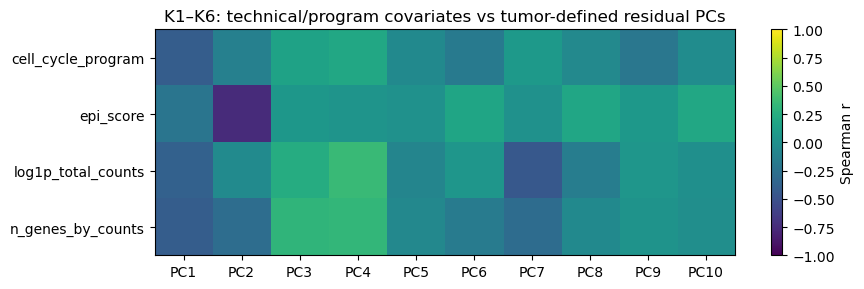

In [22]:
# Heatmap-style display of continuous technical correlations.
piv = (tech_corr[tech_corr["scope"] == "K1_to_K6"]
       .pivot(index="covariate", columns="residual_pc", values="spearman_r"))
fig, ax = plt.subplots(figsize=(9, max(3, 0.55*len(piv))))
im = ax.imshow(piv.values, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels([f"PC{x}" for x in piv.columns])
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index)
ax.set_title("K1–K6: technical/program covariates vs tumor-defined residual PCs")
plt.colorbar(im, ax=ax, label="Spearman r")
plt.tight_layout()
fig.savefig(os.path.join(OUTDIR, f"tumor_residual_technical_correlations_K{K}.pdf"), bbox_inches="tight")
plt.show()

# 9. Does the biological residual story survive malignant-only PCA?

PC numbers are not expected to match after refitting-the axes can rotate. The robust question is whether the **same programs remain strongly associated with *some* leading residual axis** when N1/N2 are excluded from the PCA fit.

For every curated program, we therefore compare the maximum absolute Spearman correlation across the first 10 residual PCs under:

1. the original residual PCA fitted on all Burdziak cells, and
2. the K1–K6-only residual PCA.

Both correlations are evaluated on K1–K6 cells only, so the comparison is about the fitted axes, not a change of evaluated cells.

In [23]:
def program_axis_correlations(coords, program_scores_df, mask, n_pcs=10):
    rows = []
    P = program_scores_df.to_numpy()
    names = list(program_scores_df.columns)
    for j in range(min(n_pcs, coords.shape[1])):
        x = coords[mask, j]
        for gi, pname in enumerate(names):
            y = P[mask, gi]
            r = spearmanr(x, y, nan_policy="omit").correlation
            rows.append({"pc":j+1,"program":pname,"spearman_r":r,"abs_r":abs(r) if np.isfinite(r) else np.nan})
    return pd.DataFrame(rows)

corr_allfit = program_axis_correlations(coords_res_all, program_scores, tumor_mask, TOP_RESIDUAL_PCS)
corr_tumorfit = program_axis_correlations(coords_res_tumor_defined_all, program_scores, tumor_mask, TOP_RESIDUAL_PCS)

best_all = (corr_allfit.sort_values("abs_r", ascending=False).groupby("program", as_index=False).first()
            .rename(columns={"pc":"best_pc_allfit","spearman_r":"rho_allfit","abs_r":"max_abs_rho_allfit"}))
best_tumor = (corr_tumorfit.sort_values("abs_r", ascending=False).groupby("program", as_index=False).first()
              .rename(columns={"pc":"best_pc_tumorfit","spearman_r":"rho_tumorfit","abs_r":"max_abs_rho_tumorfit"}))
program_retention = best_all.merge(best_tumor, on="program", how="outer")
program_retention["delta_max_abs_rho_tumor_minus_all"] = program_retention["max_abs_rho_tumorfit"] - program_retention["max_abs_rho_allfit"]
program_retention = program_retention.sort_values("max_abs_rho_tumorfit", ascending=False)
program_retention.to_csv(os.path.join(OUTDIR, f"residual_program_retention_malignant_only_K{K}.csv"), index=False)

key_programs = [
    "emt_invasion",
    "hypoxia",
    "oxidative_stress",
    "unfolded_protein_response",
    "glycolysis_metabolic_rewiring",
    "senescence_sasp",
    "therapy_resistance_stress_tolerance",
    "kras_mapk_signaling",
    "cell_cycle",
]
key_retention = program_retention[program_retention["program"].isin(key_programs)].copy()
key_retention

,program,best_pc_allfit,rho_allfit,max_abs_rho_allfit,best_pc_tumorfit,rho_tumorfit,max_abs_rho_tumorfit,delta_max_abs_rho_tumor_minus_all
9,glycolysis_metabolic_rewiring,2,-0.673466,0.673466,1,-0.662316,0.662316,-0.011150
18,senescence_sasp,1,0.553952,0.553952,2,-0.536989,0.536989,-0.016963
7,emt_invasion,2,-0.516521,0.516521,1,-0.493248,0.493248,-0.023273
13,kras_mapk_signaling,1,0.543659,0.543659,2,-0.460032,0.460032,-0.083627
4,cell_cycle,2,-0.425192,0.425192,1,-0.413273,0.413273,-0.011919
22,unfolded_protein_response,2,0.374395,0.374395,1,0.407089,0.407089,0.032695
10,hypoxia,2,-0.429287,0.429287,1,-0.406285,0.406285,-0.023002
21,therapy_resistance_stress_tolerance,1,0.274425,0.274425,6,-0.363326,0.363326,0.088901
16,oxidative_stress,1,0.335917,0.335917,3,0.361727,0.361727,0.025809


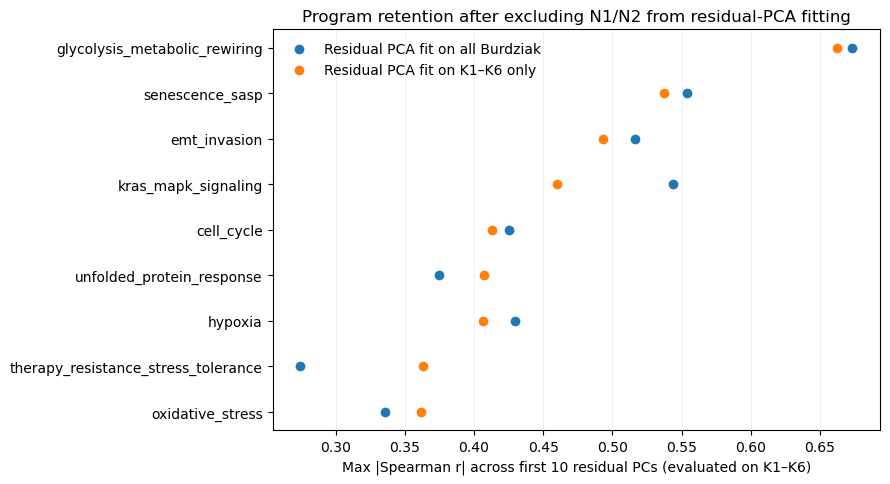

In [24]:
# Side-by-side program-retention plot for the key narrative programs.
plot_df = key_retention.sort_values("max_abs_rho_tumorfit")
y = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(9, max(4, 0.55*len(plot_df))))
ax.scatter(plot_df["max_abs_rho_allfit"], y, label="Residual PCA fit on all Burdziak")
ax.scatter(plot_df["max_abs_rho_tumorfit"], y, label="Residual PCA fit on K1–K6 only")
ax.set_yticks(y); ax.set_yticklabels(plot_df["program"])
ax.set_xlabel("Max |Spearman r| across first 10 residual PCs (evaluated on K1–K6)")
ax.set_title("Program retention after excluding N1/N2 from residual-PCA fitting")
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
fig.savefig(os.path.join(OUTDIR, f"residual_program_retention_K{K}.pdf"), bbox_inches="tight")
plt.show()

# 10. AE2 final decision gate — audited joint model

AE2 is closed once the primary clean joint seed has regenerated:

- K-sensitivity curves for developmental projection and residual magnitude;
- cell-level distributions with biological-sample points;
- matched-dimensional random-subspace benchmark;
- held-out-development reconstruction;
- K-series-only residual PCA, with N1/N2 projected after the axes are fit;
- technical/sample diagnostics;
- retention of cancer-associated transcriptional programs on leading K-series-defined residual axes.

Do **not** use the old foregut/ductal/acinar/biliary axis-specific numbers as the final biological result. AE3 AUDITED reconstructs the corrected Qiu-supported directions in this same clean embedding.


In [ ]:
# One compact index of generated files.
print("EA2 output directory:", OUTDIR)
for fn in sorted(os.listdir(OUTDIR)):
    if fn.endswith((".csv", ".pdf")):
        print(" -", fn)

WP2 output directory: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/wp2_clean_joint_seed_17
 - N1N2_residual_span_alignment_K75.csv
 - cancer_program_marker_coverage.csv
 - cancer_program_scores_log1pCPM.csv
 - cell_and_sample_distributions_K75.pdf
 - cell_metrics_K75.csv
 - heldout_development_K75.csv
 - hierarchical_bootstrap_summary_K75.csv
 - hierarchical_bootstrap_transition_metrics_K75.csv
 - k_sensitivity_by_condition.csv
 - k_sensitivity_by_state.csv
 - k_sensitivity_overview.pdf
 - k_sensitivity_residual_subspace_stability.csv
 - k_sensitivity_summary.csv
 - k_sensitivity_transition_geometry.csv
 - random_direction_summary_K75.csv
 - random_subspace_null_K75.csv
 - random_subspace_summary_K75.csv
 - residual_program_retention_K75.pdf
 - residual_program_retention_malignant_only_K75.csv
 - sample_label_permutation_null_K75.csv
 - sample_label_permutation_summary_K75.csv
 - sample_metrics_K75.csv
 - tumor_defined_residual_by_sample_K75.c